In [1]:
# Import the libraries we need
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Show all columns when we print a table
pd.set_option("display.max_columns", 50)

# Paths to our raw data files
RAW_LAND = "../data/raw/cbsl_land_dataset.csv"
RAW_LVI = "../data/raw/cbsl_half_yearly_dataset.xls"

# Make the src folder importable, then load the LVI table
sys.path.append("../src")
from load_cbsl import load_lvi_half_yearly

# Load the land data (augmented, calibrated to CBSL LVI, supervisor-approved)
land = pd.read_csv(RAW_LAND)

# Load the LVI table and keep only the Overall index
lvi = load_lvi_half_yearly(RAW_LVI)[["period", "Overall"]]

# Turn the date text into real dates
land["date"] = pd.to_datetime(land["Posted_Date_new"])

print("Land shape:", land.shape)
print("Date type:", land["date"].dtype)
print("\nLast 3 LVI rows:")
print(lvi.tail(3))


Land shape: (6000, 36)
Date type: datetime64[us]

Last 3 LVI rows:
     period  Overall
15  2024-H2    236.8
16  2025-H1    256.4
17  2025-H2      NaN


In [2]:
# Make a half-year label for each listing, e.g. "2023-H2"
# Months 1 to 6 are H1, months 7 to 12 are H2
half = np.where(land["date"].dt.month <= 6, "H1", "H2")
land["period"] = land["date"].dt.year.astype(str) + "-" + half

# Join the LVI value for that half-year onto each listing
land = land.merge(lvi, on="period", how="left")
land = land.rename(columns={"Overall": "lvi_at_listing"})

# Check: rows per half-year, and the LVI value that was joined
check = land.groupby("period").agg(rows=("period", "size"),
                                   lvi=("lvi_at_listing", "first"))
print(check)

# Check: how many rows have no LVI value?
print("\nRows with missing LVI:", land["lvi_at_listing"].isna().sum())


         rows    lvi
period              
2021-H1   556  159.8
2021-H2   599  178.7
2022-H1   596  186.9
2022-H2   636  205.2
2023-H1   605  215.3
2023-H2   607  219.8
2024-H1   604  230.1
2024-H2   570  236.8
2025-H1   603  256.4
2025-H2   624    NaN

Rows with missing LVI: 624


In [3]:
# LVI value at 2025-H1 is our base level (latest published value)
LVI_BASE = lvi.loc[lvi["period"] == "2025-H1", "Overall"].iloc[0]
print("Base LVI (2025-H1):", LVI_BASE)

# Rows in 2025-H2 have no LVI yet, so we keep them aside for now
held_back = land[land["lvi_at_listing"].isna()].copy()
data = land[land["lvi_at_listing"].notna()].copy()
print("Rows used for training data:", len(data))
print("Rows kept aside (2025-H2):", len(held_back))

# Move every price to the 2025-H1 level:
# price_adj = price * LVI_base / LVI_at_listing_time
data["price_adj"] = data["Price per Perch"] * LVI_BASE / data["lvi_at_listing"]

# Compare the average price per half-year, before and after the adjustment
compare = data.groupby("period")[["Price per Perch", "price_adj"]].mean().round(0)
print("\nAverage price per perch by half-year:")
print(compare)


Base LVI (2025-H1): 256.4
Rows used for training data: 5376
Rows kept aside (2025-H2): 624

Average price per perch by half-year:
         Price per Perch  price_adj
period                             
2021-H1        2049777.0  3288879.0
2021-H2        2084192.0  2990413.0
2022-H1        2380539.0  3265758.0
2022-H2        2139574.0  2673425.0
2023-H1        2463071.0  2933263.0
2023-H2        2377641.0  2773554.0
2024-H1        2755565.0  3070520.0
2024-H2        2933951.0  3176795.0
2025-H1        2845345.0  2845345.0


Median price per perch by half-year:
         Price per Perch  price_adj
period                             
2021-H1         878000.0  1408756.0
2021-H2         924000.0  1325762.0
2022-H1         962000.0  1319726.0
2022-H2        1032500.0  1290122.0
2023-H1        1084000.0  1290932.0
2023-H2        1120000.0  1306497.0
2024-H1        1192500.0  1328801.0
2024-H2        1196000.0  1294993.0
2025-H1        1297000.0  1297000.0
Price per Perch: 47.7% change from 2021-H1 to 2025-H1
price_adj: -7.9% change from 2021-H1 to 2025-H1


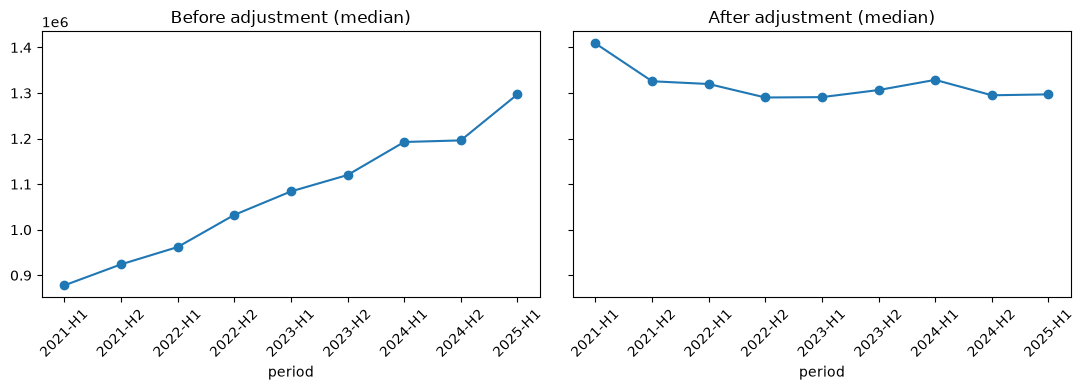

In [4]:
# Median is less affected by a few very expensive listings
med = data.groupby("period")[["Price per Perch", "price_adj"]].median().round(0)
print("Median price per perch by half-year:")
print(med)

# Percent change from first to last half-year
first, last = med.index[0], med.index[-1]
for col in med.columns:
    change = (med.loc[last, col] / med.loc[first, col] - 1) * 100
    print(f"{col}: {change:.1f}% change from {first} to {last}")

# Plot both lines side by side
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
med["Price per Perch"].plot(ax=ax[0], marker="o", title="Before adjustment (median)")
med["price_adj"].plot(ax=ax[1], marker="o", title="After adjustment (median)")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


In [5]:
# Turn the mixed Land_type text into 4 yes/no flags (1 = yes, 0 = no)
for kind in ["Residential", "Commercial", "Agricultural", "Other"]:
    data[f"type_{kind.lower()}"] = data["Land_type"].str.contains(kind).astype(int)
    held_back[f"type_{kind.lower()}"] = held_back["Land_type"].str.contains(kind).astype(int)

# Check: how many rows have each flag?
flag_cols = [c for c in data.columns if c.startswith("type_")]
print(data[flag_cols].sum())

# Check: every row should have at least one flag
print("\nRows with no flag at all:", (data[flag_cols].sum(axis=1) == 0).sum())

# Show a few rows to see the flags next to the original text
data[["Land_type"] + flag_cols].drop_duplicates().head(6)


type_residential     5187
type_commercial      2275
type_agricultural     189
type_other           1094
dtype: int64

Rows with no flag at all: 0


,Land_type,type_residential,type_commercial,type_agricultural,type_other
0,Residential,1,0,0,0
1,"Commercial, Residential",1,1,0,0
4,"Commercial, Residential, Other",1,1,0,1
6,"Residential, Other",1,0,0,1
7,"Agricultural, Commercial, Residential, Other",1,1,1,1
14,"Agricultural, Commercial, Residential",1,1,1,0


In [6]:
# Columns to keep for modelling
id_cols = ["Address_ID", "Address", "date", "period"]
size_col = ["Land_size(Perches)"]
flag_cols = ["type_residential", "type_commercial", "type_agricultural", "type_other"]
amenity_cols = [c for c in data.columns
                if c.startswith("min_dist_") or c.startswith("count_")]
location_cols = ["Distance from fort"]
feature_cols = size_col + flag_cols + location_cols + amenity_cols

# Target: price at the 2025-H1 level, then its log
data["log_price_adj"] = np.log(data["price_adj"])
target_cols = ["Price per Perch", "price_adj", "log_price_adj"]

# Build the final table
final = data[id_cols + feature_cols + target_cols].reset_index(drop=True)

# Same columns for the 2025-H2 rows (kept aside, no target)
aside = held_back[id_cols + feature_cols + ["Price per Perch"]].reset_index(drop=True)

# Save both files to the processed folder
final.to_csv("../data/processed/land_model_data.csv", index=False)
aside.to_csv("../data/processed/land_2025H2_aside.csv", index=False)

print("Final table shape:", final.shape)
print("Number of features:", len(feature_cols))
print("Missing values:", final.isna().sum().sum())
print("Aside table shape:", aside.shape)
final.head(3)


Final table shape: (5376, 39)
Number of features: 32
Missing values: 0
Aside table shape: (624, 37)


,Address_ID,Address,date,period,Land_size(Perches),type_residential,type_commercial,type_agricultural,type_other,Distance from fort,count_govtschools_A,min_dist_govtschools_a,count_govtschools_B,min_dist_govtschools_b,count_semigovtschools,min_dist_semigovtschools,count_intlschools,min_dist_intlschools,count_uni,min_dist_uni,min_dist_nearest_express,min_dist_nearest_railway,min_dist_nearest_bank,count_banks_within_2km,min_dist_nearest_FinanceCompany,count_FinanceCompanies_within_2km,min_dist_nearest_Govt_Hospital,count_Govt_Hospitals,min_dist_nearest_Pvt_Hospital,count_Pvt_Hospital,min_dist_nearest_Pvt_Med_center,count_Pvt_Med_Centers,min_dist_nearest_Supermarket,count_Supermarkets_within2km,min_dist_nearest_Fuel_station,count_Fuel_Stations_within2km,Price per Perch,price_adj,log_price_adj
0,18,bope,2023-08-13,2023-H2,10.0,1,0,0,0,36.09,0,18.656149,1,0.546813,0,10.478451,0,21.224113,0,5.192049,16.694409,3.421132,4.421975,0,4.385422,0,15.857647,0,4.668703,0,11.631035,0,4.992931,0,9.219190,0,305000.0,3.557871e+05,12.782088
1,10,thalawathugoda,2025-02-15,2025-H1,27.0,1,1,0,0,14.19,0,3.947032,1,1.741785,0,3.685223,0,2.039184,0,4.333994,4.620078,3.239813,0.047188,14,0.311696,1,4.725444,0,0.346662,1,2.606001,0,0.207307,9,1.832361,1,3146000.0,3.146000e+06,14.961642
2,19,boralesgamuwa,2021-09-16,2021-H2,17.5,1,1,0,0,13.98,0,4.016691,1,0.429339,0,2.727913,0,3.818289,1,1.440498,8.830429,2.212403,0.071858,10,0.087264,2,1.864090,1,4.973745,0,0.811285,1,0.100747,11,0.886449,1,3386000.0,4.858256e+06,15.396190
